In [7]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

from shapely.geometry import Point

In [8]:
print(gpd.__version__)

1.2.0


In [9]:
data = {
    "name": [
        "Charger A",
        "Charger B",
        "Charger C",
        "Charger D"
    ],
    "latitude": [
        60.3913,
        60.3775,
        60.4050,
        60.3650
    ],
    "longitude": [
        5.3221,
        5.3350,
        5.2900,
        5.3450
    ],
    "power_kw": [
        150,
        300,
        50,
        200
    ]
}

df = pd.DataFrame(data)

df

,name,latitude,longitude,power_kw
0,Charger A,60.3913,5.3221,150
1,Charger B,60.3775,5.3350,300
2,Charger C,60.4050,5.2900,50
3,Charger D,60.3650,5.3450,200


In [10]:
chargers = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(
        df["longitude"],
        df["latitude"]
    ),
    crs="EPSG:4326"
)

chargers

,name,latitude,longitude,power_kw,geometry
0,Charger A,60.3913,5.3221,150,POINT (5.3221 60.3913)
1,Charger B,60.3775,5.3350,300,POINT (5.335 60.3775)
2,Charger C,60.4050,5.2900,50,POINT (5.29 60.405)
3,Charger D,60.3650,5.3450,200,POINT (5.345 60.365)


In [11]:
type(chargers)

geopandas.geodataframe.GeoDataFrame

In [12]:
chargers.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [13]:
chargers.distance(chargers.iloc[0].geometry)

C:\Users\hcloe\AppData\Local\Temp\ipykernel_12760\1420362777.py:1: UserWarning: Geometry is in a geographic CRS. Results from 'distance' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  chargers.distance(chargers.iloc[0].geometry)


0    0.000000
1    0.018890
2    0.034901
3    0.034873
dtype: float64

In [ ]:
# Project to a metric CRS for distance calculations

chargers_utm = chargers.to_crs(epsg=25832)  # UTM zone 32N
chargers_utm.crs

<Projected CRS: EPSG:25832>
Name: ETRS89 / UTM zone 32N
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Europe between 6°E and 12°E: Austria; Denmark - onshore and offshore; Germany - onshore and offshore; Italy - onshore and offshore; Norway including Svalbard - onshore and offshore; Spain - offshore.
- bounds: (6.0, 36.53, 12.01, 84.01)
Coordinate Operation:
- name: UTM zone 32N
- method: Transverse Mercator
Datum: European Terrestrial Reference System 1989 ensemble
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

In [15]:
chargers_utm[["name", "geometry"]]

,name,geometry
0,Charger A,POINT (297353.933 6700648.345)
1,Charger B,POINT (297978.706 6699073.366)
2,Charger C,POINT (295672.471 6702271.741)
3,Charger D,POINT (298452.318 6697652.011)


In [16]:
start = gpd.GeoDataFrame(
    {"name": ["Start"]},
    geometry=[
        Point(5.3242, 60.3920)
    ],
    crs="EPSG:4326"
)

start

,name,geometry
0,Start,POINT (5.3242 60.392)


In [17]:
start_utm = start.to_crs(epsg=25832)

In [18]:
# Calculate distances from start point to each charger
chargers_utm["distance_m"] = chargers_utm.distance(
    start_utm.geometry.iloc[0]
)

chargers_utm[
    ["name", "power_kw", "distance_m"]
].sort_values("distance_m")

,name,power_kw,distance_m
0,Charger A,150,139.623763
1,Charger B,300,1722.048135
2,Charger C,50,2377.772847
3,Charger D,200,3220.000430


In [19]:
# Find nearest charger
nearest_idx = chargers_utm["distance_m"].idxmin()

nearest_charger = chargers_utm.loc[nearest_idx]

nearest_charger

name                                            Charger A
latitude                                          60.3913
longitude                                          5.3221
power_kw                                              150
geometry      POINT (297353.9327266291 6700648.345108973)
distance_m                                     139.623763
Name: 0, dtype: object

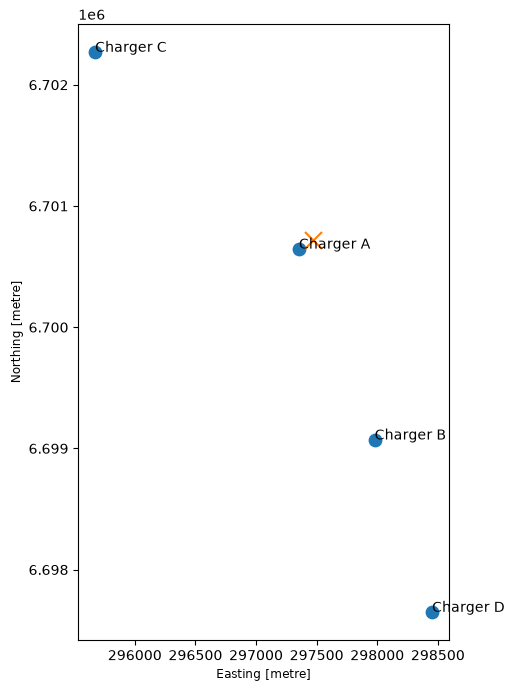

In [20]:
fig, ax = plt.subplots(figsize=(8, 8))

chargers_utm.plot(
    ax=ax,
    markersize=80
)

start_utm.plot(
    ax=ax,
    marker="x",
    markersize=150
)

for _, row in chargers_utm.iterrows():
    ax.annotate(
        row["name"],
        (row.geometry.x, row.geometry.y)
    )

plt.show()

In [ ]:
# Find chargers within 2 km of starting point
buffer_2km = start_utm.buffer(2000)

within_2km = chargers_utm[
    chargers_utm.geometry.within(buffer_2km.iloc[0])
]

within_2km

,name,latitude,longitude,power_kw,geometry,distance_m
0,Charger A,60.3913,5.3221,150,POINT (297353.933 6700648.345),139.623763
1,Charger B,60.3775,5.3350,300,POINT (297978.706 6699073.366),1722.048135
